# Khám phá dữ liệu ảnh

Xem phân bố lớp, ảnh lỗi, kích thước và ảnh mẫu. Nhãn lấy từ tên thư mục cha; dữ liệu gốc không thay đổi.

In [ ]:
# Thư viện đọc dữ liệu và vẽ biểu đồ.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

plt.style.use("seaborn-v0_8-whitegrid")

# Lấy thư mục gốc khi notebook chạy từ EDA.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "eda" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "VN_trash_classification"
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

RANDOM_SEED = 42

print(f"Thư mục dự án: {PROJECT_DIR}")
print(f"Dataset gốc: {DATA_DIR}")
print(f"Dataset đã tồn tại: {DATA_DIR.exists()}")

Thư mục dự án: c:\Users\XPS\Desktop\trash-image-classification
Dataset gốc: c:\Users\XPS\Desktop\trash-image-classification\data\VN_trash_classification
Dataset đã tồn tại: True


## 1. Danh sách ảnh

Chỉ dùng ảnh trong `VN_trash_classification/Train` và `Test`. Nhãn lấy từ thư mục lớp.

In [ ]:
records = []

for split in ("Train", "Test"):
    split_dir = DATA_DIR / split
    if not split_dir.exists():
        continue

    for image_path in sorted(split_dir.rglob("*")):
        if image_path.is_file() and image_path.suffix.lower() in SUPPORTED_EXTENSIONS:
            records.append(
                {
                    "path": image_path,
                    "label": image_path.parent.name,
                    "extension": image_path.suffix.lower(),
                }
            )

images_df = pd.DataFrame(records, columns=["path", "label", "extension"])

if images_df.empty:
    print("Chưa tìm thấy ảnh trong Train/Test của dataset.")
else:
    print(f"Tổng số ảnh: {len(images_df):,}")
    print(f"Số lớp: {images_df['label'].nunique()}")
    print("Các lớp:", sorted(images_df["label"].unique()))
    display(images_df.head())

Tổng số ảnh: 12,091
Số lớp: 9
Các lớp: ['Alu', 'Carton', 'Foam_box', 'Milk_box', 'Other', 'PET', 'Paper', 'Paper_cup', 'Plastic_cup']


,path,label,extension
0,c:\Users\XPS\Desktop\trash-image-classificatio...,Alu,.jpg
1,c:\Users\XPS\Desktop\trash-image-classificatio...,Alu,.jpg
2,c:\Users\XPS\Desktop\trash-image-classificatio...,Alu,.jpg
3,c:\Users\XPS\Desktop\trash-image-classificatio...,Alu,.jpg
4,c:\Users\XPS\Desktop\trash-image-classificatio...,Alu,.jpg


## 2. Số ảnh theo lớp

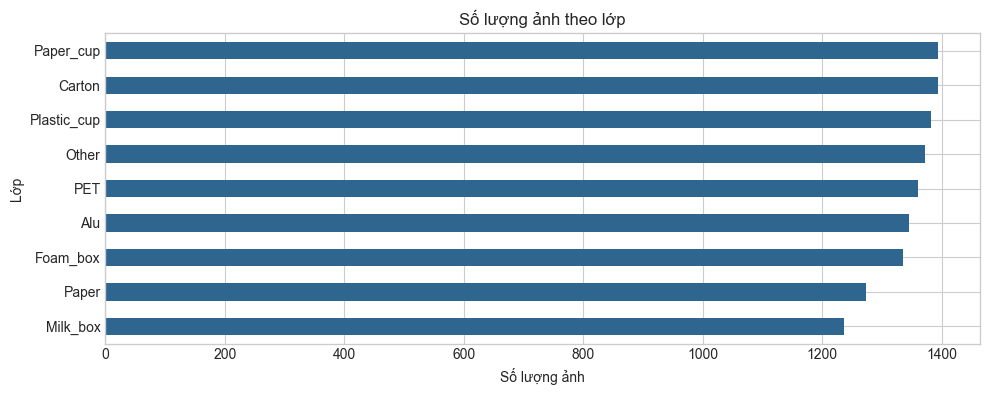

,image_count,percentage
label,,
Carton,1394,11.53
Paper_cup,1394,11.53
Plastic_cup,1382,11.43
Other,1372,11.35
PET,1360,11.25
Alu,1345,11.12
Foam_box,1335,11.04
Paper,1273,10.53
Milk_box,1236,10.22


Tỷ lệ lớp lớn nhất / nhỏ nhất: 1.13 lần


In [9]:
if images_df.empty:
    print("Không thể vẽ phân bố lớp vì chưa có dữ liệu.")
else:
    label_counts = images_df["label"].value_counts().sort_values(ascending=True)
    imbalance_ratio = label_counts.max() / label_counts.min()

    fig, ax = plt.subplots(figsize=(10, max(4, len(label_counts) * 0.45)))
    label_counts.plot.barh(ax=ax, color="#2f6690")
    ax.set_title("Số lượng ảnh theo lớp")
    ax.set_xlabel("Số lượng ảnh")
    ax.set_ylabel("Lớp")
    plt.tight_layout()
    plt.show()

    summary_df = label_counts.rename("image_count").to_frame()
    summary_df["percentage"] = (summary_df["image_count"] / len(images_df) * 100).round(2)
    display(summary_df.sort_values("image_count", ascending=False))
    print(f"Tỷ lệ lớp lớn nhất / nhỏ nhất: {imbalance_ratio:.2f} lần")

## 3. Kiểm tra ảnh

In [10]:
metadata = []
corrupt_images = []

for image_path in images_df["path"] if not images_df.empty else []:
    try:
        with Image.open(image_path) as image:
            metadata.append(
                {
                    "path": image_path,
                    "width": image.width,
                    "height": image.height,
                    "channels": len(image.getbands()),
                    "format": image.format,
                    "aspect_ratio": round(image.width / image.height, 3),
                }
            )
    except (UnidentifiedImageError, OSError):
        corrupt_images.append(image_path)

metadata_df = pd.DataFrame(metadata)

print(f"Ảnh đọc được: {len(metadata_df):,}")
print(f"Ảnh lỗi: {len(corrupt_images):,}")
if corrupt_images:
    print("Một số file lỗi:")
    for path in corrupt_images[:10]:
        print(f"- {path}")

if not metadata_df.empty:
    display(metadata_df[["width", "height", "channels", "format", "aspect_ratio"]].describe(include="all"))

Ảnh đọc được: 12,091
Ảnh lỗi: 0


,width,height,channels,format,aspect_ratio
count,12091.000000,12091.000000,12091.000000,12091,12091.000000
unique,NaN,NaN,NaN,5,NaN
top,NaN,NaN,NaN,JPEG,NaN
freq,NaN,NaN,NaN,11492,NaN
mean,697.256141,627.051278,3.000000,NaN,1.146382
std,722.840650,673.249984,0.279726,NaN,0.310658
min,50.000000,50.000000,1.000000,NaN,0.128000
25%,246.000000,225.000000,3.000000,NaN,1.000000
50%,479.000000,384.000000,3.000000,NaN,1.000000
75%,800.000000,720.000000,3.000000,NaN,1.333000


## 4. Kích thước và định dạng

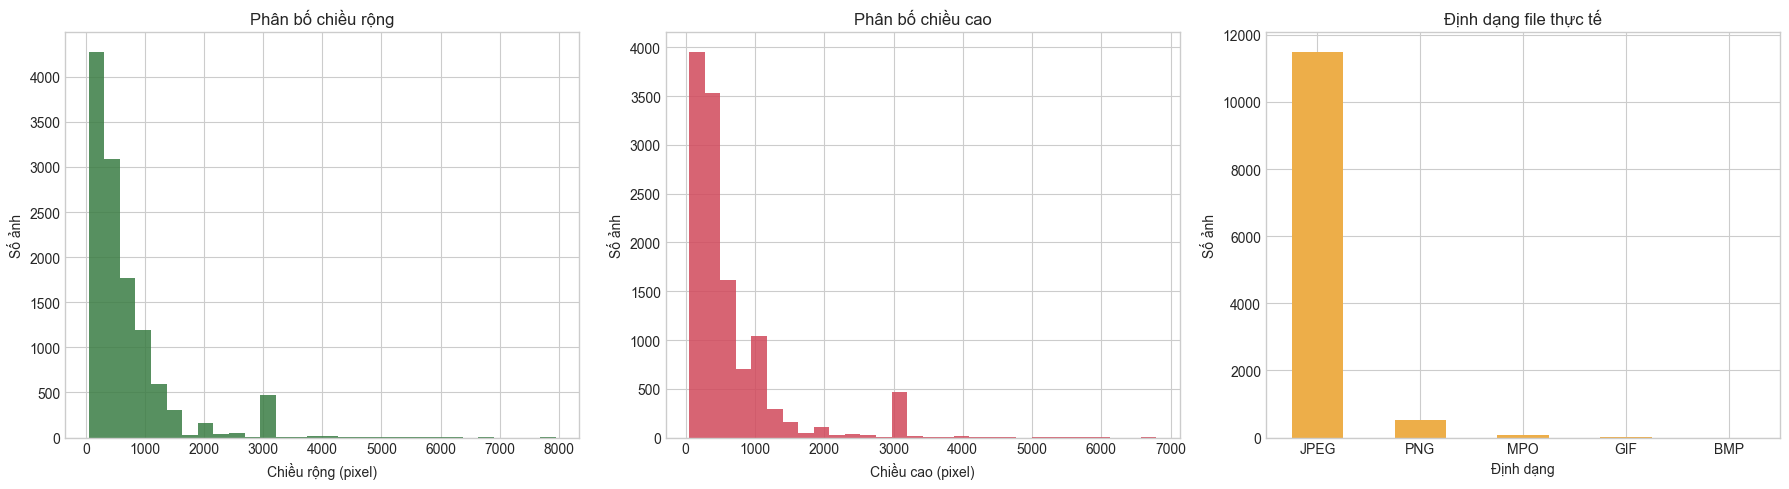

Tỷ lệ khung hình nhỏ nhất: 0.128
Tỷ lệ khung hình lớn nhất: 6.4


In [11]:
if metadata_df.empty:
    print("Chưa có metadata để phân tích.")
else:
    figure, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].hist(metadata_df["width"], bins=30, color="#3a7d44", alpha=0.85)
    axes[0].set_title("Phân bố chiều rộng")
    axes[0].set_xlabel("Chiều rộng (pixel)")
    axes[0].set_ylabel("Số ảnh")

    axes[1].hist(metadata_df["height"], bins=30, color="#d1495b", alpha=0.85)
    axes[1].set_title("Phân bố chiều cao")
    axes[1].set_xlabel("Chiều cao (pixel)")
    axes[1].set_ylabel("Số ảnh")

    metadata_df["format"].value_counts().plot.bar(ax=axes[2], color="#edae49")
    axes[2].set_title("Định dạng file thực tế")
    axes[2].set_xlabel("Định dạng")
    axes[2].set_ylabel("Số ảnh")
    axes[2].tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

    print("Tỷ lệ khung hình nhỏ nhất:", metadata_df["aspect_ratio"].min())
    print("Tỷ lệ khung hình lớn nhất:", metadata_df["aspect_ratio"].max())

## 5. Trực quan hóa ảnh

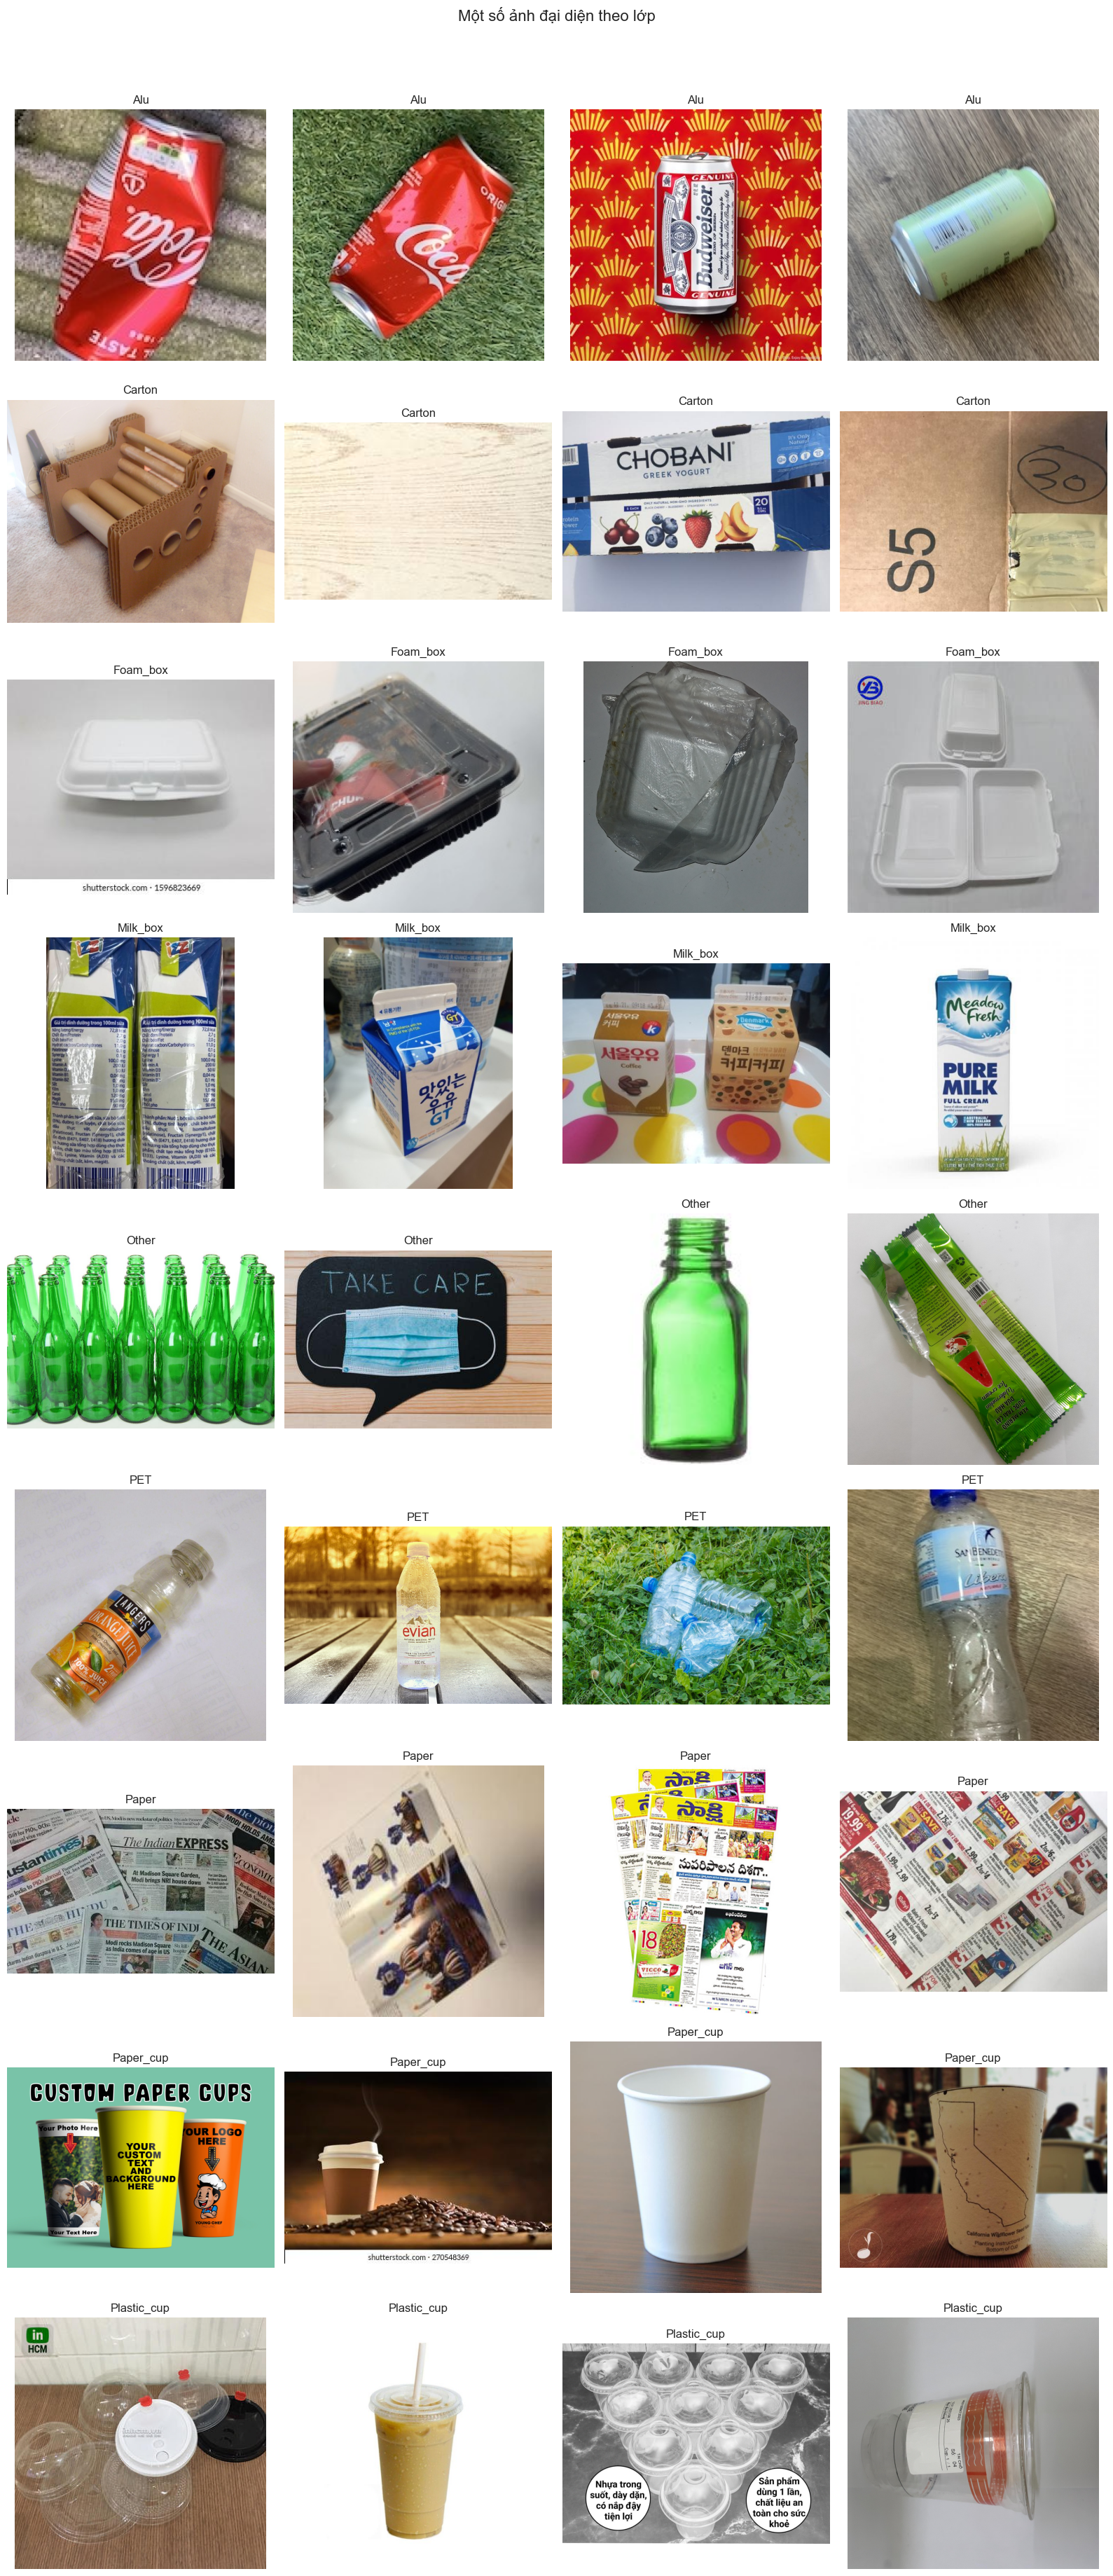

In [12]:
if images_df.empty:
    print("Chưa có ảnh để trực quan hóa.")
else:
    labels = sorted(images_df["label"].unique())
    columns = 4
    rows = len(labels)
    figure, axes = plt.subplots(rows, columns, figsize=(16, max(4, rows * 4)))
    axes = np.atleast_2d(axes)

    for row_index, label in enumerate(labels):
        examples = images_df[images_df["label"] == label].sample(
            n=min(columns, (images_df["label"] == label).sum()),
            random_state=RANDOM_SEED,
        )

        for axis in axes[row_index]:
            axis.axis("off")

        for column_index, (_, record) in enumerate(examples.iterrows()):
            try:
                with Image.open(record["path"]) as image:
                    axes[row_index, column_index].imshow(image.convert("RGB"))
                axes[row_index, column_index].set_title(label)
                axes[row_index, column_index].axis("off")
            except (UnidentifiedImageError, OSError):
                axes[row_index, column_index].set_title("Ảnh lỗi")

    plt.suptitle("Một số ảnh đại diện theo lớp", y=1.02, fontsize=16)
    plt.tight_layout()
    plt.show()